###Part 1. Data Preparation

In [37]:
from pathlib import Path
from shutil import copytree

DATA_ROOT = Path("./data")
try:
  from google.colab import drive
except ImportError:
  pass
else:
  drive.mount("/content/drive")
  drive_root = Path("/content/drive/MyDrive/datasets/cifar10")
  local_batches = DATA_ROOT / "cifar-10-batches-py"
  drive_batches = drive_root / local_batches.name
  if local_batches.is_dir() and not drive_batches.exists():
    copytree(local_batches, drive_batches)
  DATA_ROOT = drive_root

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
import torch
import torchvision
import torchvision.transforms.v2 as T

SEED = 2026
IMAGE_SIZE = 32

toTensor = T.Compose([
    T.ToImage(),
    T.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=toTensor)
train_set, val_set = torch.utils.data.random_split(
    train_set, [40000, 10000], generator=torch.Generator().manual_seed(2026)
)

test_set = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=toTensor)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=64, shuffle=False)

classes = train_set.dataset.classes

###Part 2. Model Design and Training
We implement a compact CNN using PyTorch, and train the model.

In [39]:
from functools import partial
import torch.nn as nn
import torch.nn.functional as F

class ResidualUnit(nn.Module):
  def __init__(self, in_channels, out_channels, stride=1):
    super().__init__()
    DefaultConv2d = partial(nn.Conv2d, kernel_size=3, padding=1, bias=False)
    self.main_layers = nn.Sequential(
        DefaultConv2d(in_channels, out_channels, stride=stride),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        DefaultConv2d(out_channels, out_channels, stride=1),
        nn.BatchNorm2d(out_channels)
    )
    if stride > 1:
      self.skip_connection = nn.Sequential(
          nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
          nn.BatchNorm2d(out_channels)
      )
    else:
      self.skip_connection = nn.Identity()

    #for INT8 quantization
    self.add = torch.ao.nn.quantized.FloatFunctional()

  def forward(self, x):
    return self.add.add_relu(self.main_layers(x), self.skip_connection(x))


In [40]:
class ResNet34(nn.Module):
  def __init__(self):
    super().__init__()
    layers = [
        nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7, stride=2, padding=3, bias=False),
        nn.BatchNorm2d(num_features=32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
    ]
    prev_filters = 32
    for filters in [32] * 3 + [64] * 4 + [128] * 6 + [256] * 3:
      stride = 1 if prev_filters == filters else 2
      layers.append(ResidualUnit(prev_filters, filters, stride = stride))
      prev_filters = filters
    layers += [
        nn.AdaptiveAvgPool2d(output_size=1),
        nn.Flatten(),
        nn.Linear(prev_filters, 10)
    ]
    #layers.append(nn.AdaptiveAvgPool2d(output_size=(1, 1)))
    #layers.append(nn.Flatten())
    #layers.append(nn.Linear(512, 10))
    self.resnet = nn.Sequential(*layers)

  def forward(self, inputs):
    return self.resnet(inputs)

In [41]:
torch.manual_seed(2026)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [42]:
import os

checkpoint_dir = '/content/drive/MyDrive/pytorch_checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, 'best_model.pt')

In [43]:
training_loss_hist = []
training_acc_hist = []

val_loss_hist = []
val_acc_hist = []

def train(model, optimizer, loss_fn, train_loader, val_loader, n_epochs, start_epoch=0, min_val_loss=float("inf")):
  training_loss_hist.clear()
  training_acc_hist.clear()
  val_loss_hist.clear()
  val_acc_hist.clear()
  for epoch in range(n_epochs):
    model.train()
    total_train_loss = 0
    train_correct_pred = 0
    for X_batch, y_batch in train_loader:
      X_batch = X_batch.to(device)
      y_batch = y_batch.to(device)
      y_pred = model(X_batch)
      train_loss = loss_fn(y_pred, y_batch)
      total_train_loss += train_loss.item() * y_batch.size(0)

      values, indices = torch.max(y_pred, dim=1, keepdim=True)
      train_correct_pred += (indices == y_batch.unsqueeze(1)).sum().item()

      train_loss.backward()
      optimizer.step()
      optimizer.zero_grad()

    train_accuracy = train_correct_pred / len(train_loader.dataset)

    mean_loss = total_train_loss / len(train_loader.dataset)
    print(f"epoch: {epoch+1}/{n_epochs}, loss: {mean_loss:.4f}, Train_Accuracy: {train_accuracy:.4f}")

    training_loss_hist.append(mean_loss)
    training_acc_hist.append(train_accuracy)

    model.eval()
    total_val_loss = 0
    val_correct_pred = 0
    with torch.no_grad():
      for X_val_batch, y_val_batch in val_loader:
        X_val_batch = X_val_batch.to(device)
        y_val_batch = y_val_batch.to(device)
        y_pred = model(X_val_batch)
        val_loss = loss_fn(y_pred, y_val_batch)
        total_val_loss += val_loss.item() * y_val_batch.size(0)

        values, indices = torch.max(y_pred, dim=1, keepdim=True)
        val_correct_pred += (indices == y_val_batch.unsqueeze(1)).sum().item()

      mean_val_loss = total_val_loss / len(val_loader.dataset)
      val_accuracy = val_correct_pred / len(val_loader.dataset)
      print(f"Validation Loss: {mean_val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}")

      val_loss_hist.append(mean_val_loss)
      val_acc_hist.append(val_accuracy)

      if mean_val_loss < min_val_loss:
        min_val_loss = mean_val_loss
        checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': mean_val_loss,
            'accuracy': val_accuracy
        }
        temp_path = checkpoint_path + ".tmp"
        torch.save(checkpoint, temp_path)
        os.replace(temp_path, checkpoint_path)
        print(f"Checkpoint saved at epoch {epoch + 1}")


In [44]:
def evaluate(model, test_loader, eval_device='cpu'):
  model.eval()
  total_test_loss = 0
  test_correct_pred = 0

  with torch.no_grad():
    for X_test_batch, y_test_batch in test_loader:
      X_test_batch = X_test_batch.to(eval_device)
      y_test_batch = y_test_batch.to(eval_device)
      y_pred = model(X_test_batch)

      test_loss = loss_fn(y_pred, y_test_batch)
      total_test_loss += test_loss.item() * y_test_batch.size(0)

      test_correct_pred += (y_pred.argmax(dim=1) == y_test_batch).sum().item()

  test_accuracy = test_correct_pred / len(test_loader.dataset)
  mean_test_loss = total_test_loss / len(test_loader.dataset)

  print(f"Test Loss: {mean_test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
  return test_accuracy

In [45]:
model = ResNet34()
model = model.to(device) ## model train 초기화
print(model)
#print(f'parameters: {sum()}')
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

ResNet34(
  (resnet): Sequential(
    (0): Conv2d(3, 32, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): ResidualUnit(
      (main_layers): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (skip_connection): Identity()
      (add): FloatFunctional(
        (activation_post_process): Identity()
      )
    )
    (5): ResidualUnit(
      (main_layers): Sequential(
        (0): Conv2d(32, 

In [46]:
train(model, optimizer, loss_fn, train_loader, val_loader, 15)

epoch: 1/15, loss: 1.5169, Train_Accuracy: 0.4454
Validation Loss: 1.3197, Validation Accuracy: 0.5315
Checkpoint saved at epoch 1
epoch: 2/15, loss: 1.1387, Train_Accuracy: 0.5954
Validation Loss: 1.0871, Validation Accuracy: 0.6148
Checkpoint saved at epoch 2
epoch: 3/15, loss: 0.9671, Train_Accuracy: 0.6609
Validation Loss: 0.9592, Validation Accuracy: 0.6588
Checkpoint saved at epoch 3
epoch: 4/15, loss: 0.8607, Train_Accuracy: 0.6985
Validation Loss: 0.9783, Validation Accuracy: 0.6634
epoch: 5/15, loss: 0.7676, Train_Accuracy: 0.7308
Validation Loss: 0.8465, Validation Accuracy: 0.7138
Checkpoint saved at epoch 5
epoch: 6/15, loss: 0.6888, Train_Accuracy: 0.7593
Validation Loss: 0.8145, Validation Accuracy: 0.7225
Checkpoint saved at epoch 6
epoch: 7/15, loss: 0.6236, Train_Accuracy: 0.7825
Validation Loss: 0.8524, Validation Accuracy: 0.7142
epoch: 8/15, loss: 0.5546, Train_Accuracy: 0.8068
Validation Loss: 0.7962, Validation Accuracy: 0.7329
Checkpoint saved at epoch 8
epoch: 9

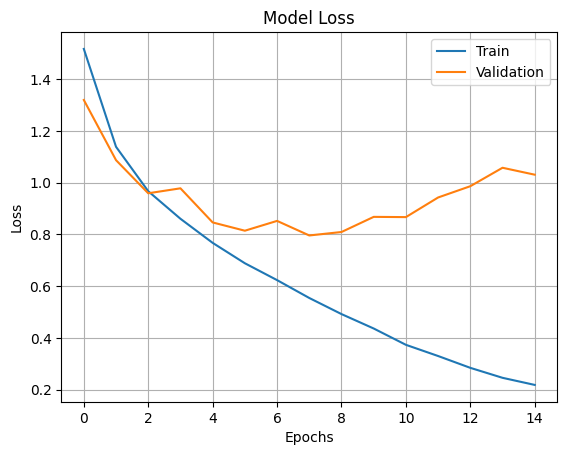

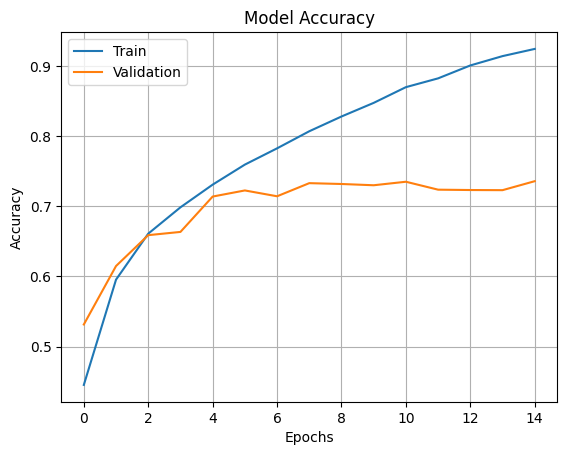

In [47]:
import matplotlib.pyplot as plt

## Loss history
plt.plot(training_loss_hist, label='Training Loss')
plt.plot(val_loss_hist, label='Validation Loss')

plt.title("Model Loss")
plt.ylabel("Loss")
plt.xlabel("Epochs")

plt.legend(["Train", "Validation"], loc="best")
plt.grid()
plt.show()

## Accuracy history
plt.plot(training_acc_hist, label='Training Accuracy')
plt.plot(val_acc_hist, label='Validation Accuracy')

plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epochs")

plt.legend(["Train", "Validation"], loc="best")
plt.grid()
plt.show()

In [48]:
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
fp32_model = model.cpu().eval()

evaluate(fp32_model, test_loader)

Test Loss: 0.8170, Test Accuracy: 0.7244


0.7244

###Part 3. Model Quantization

In [49]:
import platform
machine = platform.machine().lower()
engine = "qnnpack" if machine.startswith(("arm", "aarch")) else "x86"

###FP32 Model

In [50]:
from copy import deepcopy

torch.backends.quantized.engine = engine
fp32_cpu = deepcopy(fp32_model).cpu().eval()

###Dynamic INT8 Model

In [ ]:
from torch.ao.nn.quantized import dynamic as nnqd
from torch.ao.quantization import quantize_dynamic, QConfig, default_dynamic_qconfig, get_default_qconfig

dynamic_qconfig = QConfig(
    activation=default_dynamic_qconfig.activation,
    weight=get_default_qconfig(engine).weight,
)
qint8_dynamic_model = quantize_dynamic(
    fp32_cpu,
    {torch.nn.Conv2d: dynamic_qconfig, torch.nn.Linear: dynamic_qconfig},
    mapping={torch.nn.Conv2d: nnqd.Conv2d, nn.Linear: nnqd.Linear},
)
#X = torch.randn(3, 10)
#y_pred = qmodel(X)

/tmp/ipykernel_562/1338486181.py:8: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  qint8_dynamic_model = quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/conv.py:258: UserWarning: The current implementation of the DynamicQuantizedConv2d module has poor numerical accuracy and its use is not recommended
  qconv = cls(


###Static INT8 Model

In [52]:
class QuantizedWrapper(torch.nn.Module):
  def __init__(self, model):
    super().__init__()
    self.quant = torch.quantization.QuantStub()
    self.model = model
    self.dequant = torch.quantization.DeQuantStub()

  def forward(self, x):
    x = self.quant(x)
    x = self.model(x)
    x = self.dequant(x)
    return x

In [ ]:
from torch.ao.quantization import get_default_qconfig, QuantStub, DeQuantStub

fp32_model.eval()
model_to_quantize = QuantizedWrapper(deepcopy(fp32_cpu)).eval()
model_to_quantize.qconfig = get_default_qconfig(engine)

backbone = model_to_quantize.model.resnet

calibration_indices = torch.randperm(len(train_set), generator=torch.Generator().manual_seed(SEED))[:256]
calibration_set = torch.utils.data.Subset(train_set, calibration_indices.tolist())
calibration_loader = torch.utils.data.DataLoader(calibration_set, batch_size=64, shuffle=False)

torch.ao.quantization.prepare(model_to_quantize, inplace=True)
with torch.inference_mode():
  for X_batch, _ in calibration_loader:
    model_to_quantize(X_batch)
torch.ao.quantization.convert(model_to_quantize, inplace=True)

/tmp/ipykernel_562/3297865460.py:13: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.prepare(model_to_quantize, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future

QuantizedWrapper(
  (quant): Quantize(scale=tensor([0.0157]), zero_point=tensor([64]), dtype=torch.quint8)
  (model): ResNet34(
    (resnet): Sequential(
      (0): QuantizedConv2d(3, 32, kernel_size=(7, 7), stride=(2, 2), scale=0.06441119313240051, zero_point=64, padding=(3, 3), bias=False)
      (1): QuantizedBatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (4): ResidualUnit(
        (main_layers): Sequential(
          (0): QuantizedConv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), scale=0.20809507369995117, zero_point=76, padding=(1, 1), bias=False)
          (1): QuantizedBatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU()
          (3): QuantizedConv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), scale=0.10744892805814743, zero_point=79, padding=(1, 1), bias=False)
       

###Comparison on Model file size

In [54]:
from io import BytesIO

def model_size_mib(model):
  with BytesIO() as buffer:
    torch.save(model.state_dict(), buffer)
    return buffer.tell() / (1024 ** 2)

fp32_size = model_size_mib(fp32_cpu)
print(f"FP32_Model size: {fp32_size:.2f} MB")

staticINT8_size = model_size_mib(model_to_quantize)
print(f"Quantized Model size: {staticINT8_size:.2f} MB")

dynamicINT8_size = model_size_mib(qint8_dynamic_model)
print(f"Dynamically Quantized Model size: {dynamicINT8_size:.2f} MB")

FP32_Model size: 20.44 MB
Quantized Model size: 5.35 MB
Dynamically Quantized Model size: 5.32 MB


###Comparison on inference time on CPU

In [ ]:
import time

class CFG:
  sampling_size = 10000

data = torch.randn(CFG.sampling_size, 3, 32, 32)
batch_size = 64
start_time = time.time()
with torch.no_grad():
  for batch in torch.utils.data.DataLoader(data, batch_size=batch_size, shuffle=False):
    out = fp32_cpu(batch)
fp32_elapsed = round((time.time()-start_time), 5)
print(f"FP32 elapsed time: {fp32_elapsed} seconds")

start_time = time.time()
with torch.no_grad():
  for batch in torch.utils.data.DataLoader(data, batch_size=batch_size, shuffle=False):
    sQout = model_to_quantize(batch)
sQelapsed = round((time.time()-start_time), 5)
print(f"Quantization elapsed time: {sQelapsed} seconds")

start_time = time.time()
with torch.no_grad():
  for batch in torch.utils.data.DataLoader(data, batch_size=batch_size, shuffle=False):
    dQout = qint8_dynamic_model(batch)
dQelapsed = round((time.time()-start_time), 5)
print(f"Dynamic Quantization elapsed time: {dQelapsed} seconds")


FP32 elapsed time: 8.80795 seconds
Quantization elapsed time: 5.24677 seconds
Dynamic Quantization elapsed time: 7.53305 seconds


###Comparison on Accuracy

In [56]:
from torch.utils.benchmark import Timer

print("FP32")
fp32_acc = evaluate(fp32_model, test_loader)
print(f"FP32 Accuracy:", fp32_acc)

print("Static INT8")
quantized_acc = evaluate(model_to_quantize, test_loader)
print(f"Quantized Accuracy:", quantized_acc)
print(f"Accuracy change: {(fp32_acc - quantized_acc) / fp32_acc * 100:.2f}%")

print("Dynamic INT8")
dynamic_acc = evaluate(qint8_dynamic_model, test_loader)
print(f"Dynamic Accuracy:", dynamic_acc)
print(f"Accuracy change: {(fp32_acc - dynamic_acc) / fp32_acc *100:.2f}%")


FP32
Test Loss: 0.8170, Test Accuracy: 0.7244
FP32 Accuracy: 0.7244
Static INT8
Test Loss: 0.8220, Test Accuracy: 0.7209
Quantized Accuracy: 0.7209
Accuracy change: 0.48%
Dynamic INT8
Test Loss: 15.0092, Test Accuracy: 0.1405
Dynamic Accuracy: 0.1405
Accuracy change: 80.60%
